# 1. Discrete and Continuous Uniforms

Computers generate pseudo-random numbers using discrete states. We first generate discrete uniform integers and scale them to the interval [0, 1].

The required transformation is:

\[
U = \frac{X}{N}
\]

For a small value of N, the possible values are visibly separated. For a very large N, the gaps become extremely small and the result looks continuous.


## 1.1 Discrete Generation

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Number of samples
n_samples = 10_000

# Small N
N = 10

# Generate X ∈ {0, 1, ..., N}
X = np.random.randint(0, N + 1, size=n_samples)

print("First 20 values of X:")
print(X[:20])

print("Minimum value:", X.min())
print("Maximum value:", X.max())

First 20 values of X:
[ 3  4  6 10  6  0  5  4  7  4  1  9  0 10  5  6  9  0  0  2]
Minimum value: 0
Maximum value: 10


## 1.2 Linear Transformation

In [24]:
# Scale X to [0, 1]
U = X / N

print("First 20 values of U:")
print(U[:20])

print("Minimum value:", U.min())
print("Maximum value:", U.max())

First 20 values of U:
[0.3 0.4 0.6 1.  0.6 0.  0.5 0.4 0.7 0.4 0.1 0.9 0.  1.  0.5 0.6 0.9 0.
 0.  0.2]
Minimum value: 0.0
Maximum value: 1.0


## 1.3 Observing Granularity for N = 10

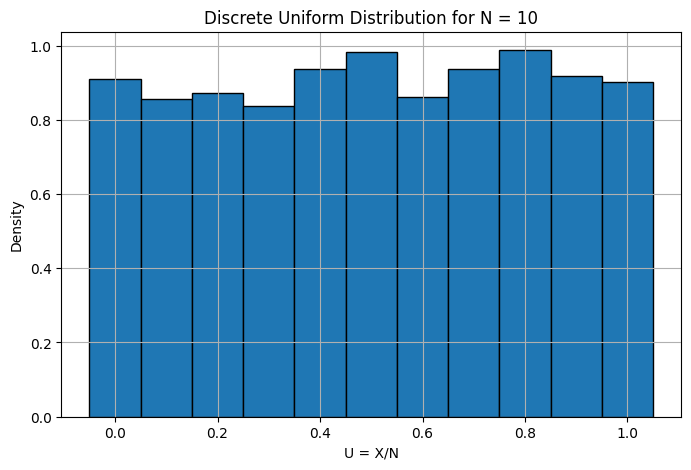

In [25]:
plt.figure(figsize=(8, 5))

plt.hist(
    U,
    bins=np.linspace(-0.05, 1.05, 12),
    density=True,
    edgecolor="black"
)

plt.xlabel("U = X/N")
plt.ylabel("Density")
plt.title("Discrete Uniform Distribution for N = 10")

plt.show()

For N = 10, only 11 possible normalized values exist:

\[
0, 0.1, 0.2, \ldots, 1
\]

Therefore, the histogram shows clear discrete steps.


## 1.4 Continuous Limit for N = 2³² − 1

In [26]:
# Massive value of N
N_large = 2**32 - 1

# Generate 10,000 discrete uniform integers
X_large = np.random.randint(
    0,
    N_large + 1,
    size=n_samples,
    dtype=np.int64
)

# Transform to [0, 1]
U_large = X_large / N_large

print("N =", N_large)
print("First 20 values of X:")
print(X_large[:20])

print("\nFirst 20 values of U:")
print(U_large[:20])

N = 4294967295
First 20 values of X:
[1261057784 1185555738 2264351046 2121553959 2648757979  526026161
  610052079 1062150008 4006305449 2966164480  888227187 1591884282
  785850150 3193124056 4209747241 4005747638 2049619018   11495813
  572556524 1351920980]

First 20 values of U:
[0.2936129  0.27603371 0.52721031 0.49396277 0.61671203 0.12247501
 0.14203882 0.24730107 0.93279068 0.69061399 0.20680651 0.37063944
 0.18297    0.74345713 0.98015816 0.9326608  0.47721412 0.00267658
 0.1333087  0.31476863]


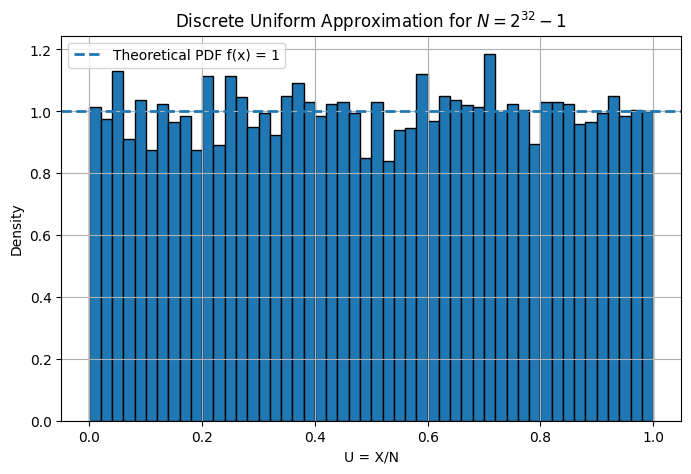

In [27]:
plt.figure(figsize=(8, 5))

plt.hist(
    U_large,
    bins=50,
    density=True,
    edgecolor="black"
)

# Theoretical continuous Uniform(0,1) PDF
plt.axhline(
    y=1,
    linestyle="--",
    linewidth=2,
    label="Theoretical PDF f(x) = 1"
)

plt.xlabel("U = X/N")
plt.ylabel("Density")
plt.title(r"Discrete Uniform Approximation for $N = 2^{32}-1$")
plt.legend()

plt.show()

For the very large N, the spacing between consecutive possible values is

\[
\frac{1}{N}
\]

which is extremely small. The discrete gaps are therefore visually negligible, so the histogram approaches the continuous uniform PDF:

f(x)=1

## 1.5 Moment Verification: Empirical Variance

In [28]:
# Theoretical continuous uniform variance
theoretical_variance = 1 / 12

# Empirical variances
variance_small = np.var(U, ddof=1)
variance_large = np.var(U_large, ddof=1)

print("Theoretical variance =", theoretical_variance)

print("\nEmpirical variance for N = 10:")
print(variance_small)

print("\nEmpirical variance for N = 2^32 - 1:")
print(variance_large)

Theoretical variance = 0.08333333333333333

Empirical variance for N = 10:
0.09927341494149415

Empirical variance for N = 2^32 - 1:
0.08337541000607897


In [29]:
print("\n---------- Variance Comparison ----------")

print(f"Theoretical variance (1/12): {theoretical_variance:.6f}")
print(f"Empirical variance, N=10:    {variance_small:.6f}")
print(f"Empirical variance, large N: {variance_large:.6f}")

print("\n---------- Absolute Errors ----------")

error_small = abs(variance_small - theoretical_variance)
error_large = abs(variance_large - theoretical_variance)

print(f"Error for N=10:    {error_small:.6f}")
print(f"Error for large N: {error_large:.6f}")


---------- Variance Comparison ----------
Theoretical variance (1/12): 0.083333
Empirical variance, N=10:    0.099273
Empirical variance, large N: 0.083375

---------- Absolute Errors ----------
Error for N=10:    0.015940
Error for large N: 0.000042


# 2. Generating Distributions via Inverse Transform

A standard uniform random variable

\[
U\sim Uniform(0,1)
\]

can be transformed into samples from another distribution using its inverse CDF.


## 2A. Continuous Transformation — Exponential Distribution

The assignment gives:

\[
F(x)=1-e^{-\lambda x}
\]

For \(U=F(X)\), solving for X gives:

\[
X=-\frac{\ln(1-U)}{\lambda}
\]

We use \(\lambda=2\) and generate 5,000 samples.


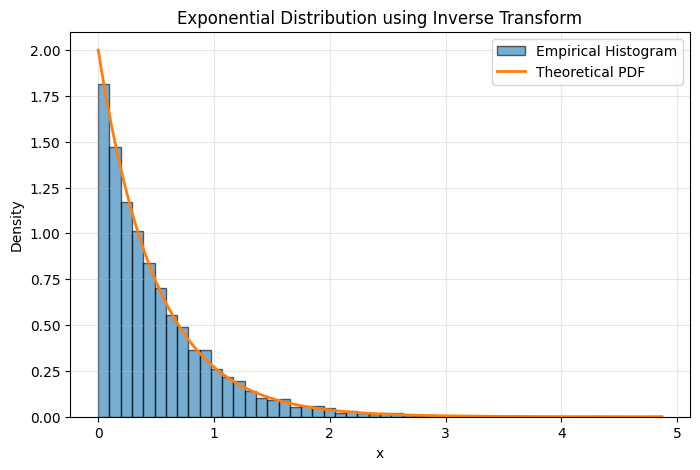

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
lambda_value = 2
n_samples = 5000

# Generate standard uniform random variables
U = np.random.uniform(0, 1, n_samples)

# Inverse CDF of Exponential distribution
# F(x) = 1 - e^(-lambda*x)
# Therefore, X = -ln(1-U) / lambda
X = -np.log(1 - U) / lambda_value

# Plot normalized empirical histogram
plt.figure(figsize=(8, 5))

plt.hist(
    X,
    bins=50,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Empirical Histogram"
)

# Theoretical PDF
x = np.linspace(0, X.max(), 500)
pdf = lambda_value * np.exp(-lambda_value * x)

# Overlay theoretical PDF
plt.plot(
    x,
    pdf,
    linewidth=2,
    label="Theoretical PDF"
)

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Exponential Distribution using Inverse Transform")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

The histogram should approximately follow the theoretical exponential curve. This verifies that the inverse transformation successfully converted uniform random values into exponential random values.


## 2B. Discrete Transformation — Step Function

The required probabilities are:

- \(p_1=0.2\)
- \(p_2=0.5\)
- \(p_3=0.3\)

The cumulative probabilities are:

\[
[0.2, 0.7, 1.0]
\]

We use `np.searchsorted` to efficiently map uniform values into their respective probability buckets.


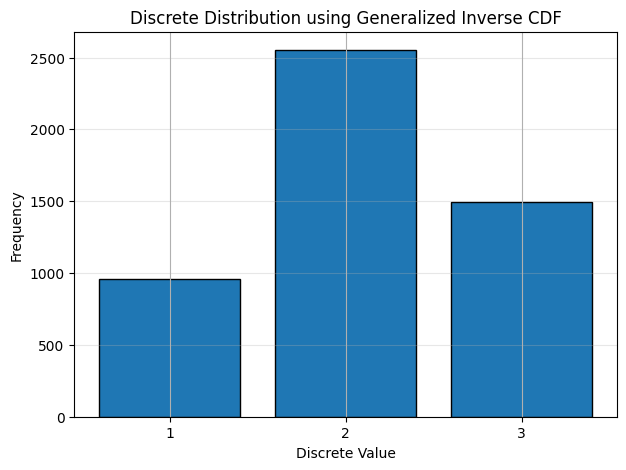

Probabilities: [0.2 0.5 0.3]
Cumulative Probabilities: [0.2 0.7 1. ]
Frequencies: [ 957 2552 1491]
Empirical Probabilities: [0.1914 0.5104 0.2982]


In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Probabilities
probabilities = np.array([0.2, 0.5, 0.3])

# Corresponding discrete values
values = np.array([1, 2, 3])

# Cumulative probabilities
cdf = np.cumsum(probabilities)

# Generate standard uniform random variables
n_samples = 5000
U = np.random.uniform(0, 1, n_samples)


# Function for generalized inverse CDF
def discrete_inverse_transform(U, cdf, values):
    indices = np.searchsorted(cdf, U, side="right")
    return values[indices]


# Transform uniform samples into discrete samples
X = discrete_inverse_transform(U, cdf, values)

# Count frequencies
frequencies = np.array([
    np.sum(X == value)
    for value in values
])

# Plot bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    values,
    frequencies,
    edgecolor="black"
)

plt.xlabel("Discrete Value")
plt.ylabel("Frequency")
plt.title("Discrete Distribution using Generalized Inverse CDF")
plt.xticks(values)
plt.grid(axis="y", alpha=0.3)

plt.show()

# Display results
print("Probabilities:", probabilities)
print("Cumulative Probabilities:", cdf)
print("Frequencies:", frequencies)
print("Empirical Probabilities:", frequencies / n_samples)

# 3. Binomial Convergence & the Infinite Limit

A Binomial random variable represents the number of successes in n independent Bernoulli trials.

The assignment asks us to simulate it by **summing independent Bernoulli trials**, then examine the sample proportion:

\[
\hat p = \frac{Y}{n}
\]

The theoretical variance is:

\[
Var(\hat p)=\frac{p(1-p)}{n}
\]

As n becomes very large, this variance approaches zero.


## 3.1 Simulate Binomial by Summing Bernoulli Trials

In [33]:
p = 0.5                 # True probability of success
n_samples = 5000        # Number of repeated experiments

# Example: n = 10 trials
n = 10

# Generate n_samples × n independent Bernoulli trials
bernoulli_trials = np.random.binomial(1, p, size=(n_samples, n))

# Sum n Bernoulli trials to obtain Y ~ Binomial(n, p)
Y = np.sum(bernoulli_trials, axis=1)

print("First 20 Binomial values (Y):")
print(Y[:20])

print("\nMinimum Y:", Y.min())
print("Maximum Y:", Y.max())


First 20 Binomial values (Y):
[4 5 5 7 5 5 4 3 5 3 0 7 6 6 3 8 3 5 7 3]

Minimum Y: 0
Maximum Y: 10


For the rolling-variance experiment, we need many independent Binomial simulations for each n. The function below still constructs each Binomial observation from Bernoulli trials; it only generates the trials in a vectorized way for speed.


## 3.2 Rolling Variance of Sample Proportions

In [34]:
# Logarithmically increasing values of n
n_values = np.logspace(
    np.log10(10),
    np.log10(100000),
    15
).astype(int)

# Remove duplicate values
n_values = np.unique(n_values)

empirical_variances = []
theoretical_variances = []

for n in n_values:

    # Generate n_samples Binomial(n, p)
    # by summing n independent Bernoulli trials
    bernoulli_trials = np.random.binomial(
        1,
        p,
        size=(n_samples, n)
    )

    Y = np.sum(bernoulli_trials, axis=1)

    # Sample proportion p_hat = Y/n
    p_hat = Y / n

    # Empirical variance of p_hat
    empirical_variance = np.var(p_hat, ddof=1)

    empirical_variances.append(empirical_variance)

    # Theoretical variance:
    # Var(p_hat) = p(1-p)/n
    theoretical_variance = p * (1 - p) / n

    theoretical_variances.append(theoretical_variance)


# Convert lists to arrays
empirical_variances = np.array(empirical_variances)
theoretical_variances = np.array(theoretical_variances)

## 3.3 Visualization — Empirical Variance vs Theoretical Decay

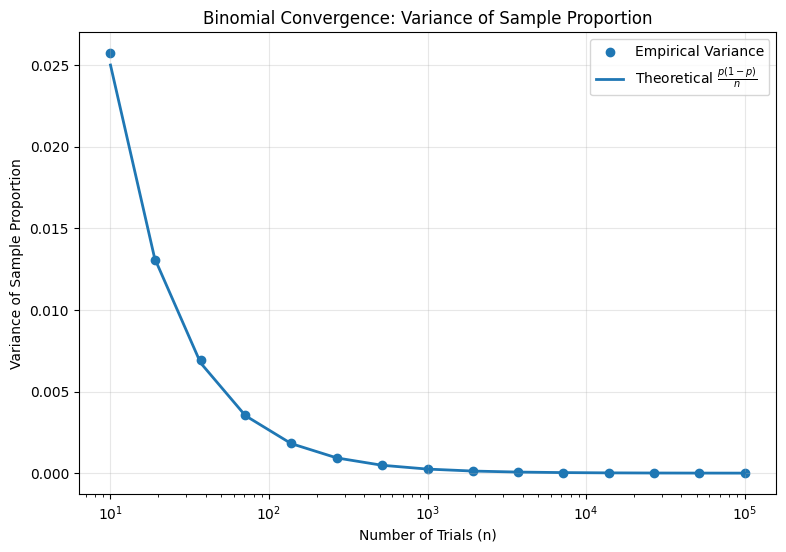


========== RESULTS ==========
n =     10 | Empirical Variance = 0.02572916 | Theoretical Variance = 0.02500000
n =     19 | Empirical Variance = 0.01307895 | Theoretical Variance = 0.01315789
n =     37 | Empirical Variance = 0.00692397 | Theoretical Variance = 0.00675676
n =     71 | Empirical Variance = 0.00358485 | Theoretical Variance = 0.00352113
n =    138 | Empirical Variance = 0.00183297 | Theoretical Variance = 0.00181159
n =    268 | Empirical Variance = 0.00090656 | Theoretical Variance = 0.00093284
n =    517 | Empirical Variance = 0.00048941 | Theoretical Variance = 0.00048356
n =   1000 | Empirical Variance = 0.00025458 | Theoretical Variance = 0.00025000
n =   1930 | Empirical Variance = 0.00013120 | Theoretical Variance = 0.00012953
n =   3727 | Empirical Variance = 0.00006556 | Theoretical Variance = 0.00006708
n =   7196 | Empirical Variance = 0.00003494 | Theoretical Variance = 0.00003474
n =  13894 | Empirical Variance = 0.00001835 | Theoretical Variance = 0.000017

In [35]:
plt.figure(figsize=(9, 6))

# Empirical variance
plt.scatter(
    n_values,
    empirical_variances,
    label="Empirical Variance"
)

# Theoretical variance curve
plt.plot(
    n_values,
    theoretical_variances,
    linewidth=2,
    label=r"Theoretical $\frac{p(1-p)}{n}$"
)

# Logarithmic x-axis
plt.xscale("log")

plt.xlabel("Number of Trials (n)")
plt.ylabel("Variance of Sample Proportion")
plt.title("Binomial Convergence: Variance of Sample Proportion")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


# ============================================================
# PRINT RESULTS
# ============================================================

print("\n========== RESULTS ==========")

for i in range(len(n_values)):
    print(
        f"n = {n_values[i]:6d} | "
        f"Empirical Variance = {empirical_variances[i]:.8f} | "
        f"Theoretical Variance = {theoretical_variances[i]:.8f}"
    )

The empirical points should closely follow the theoretical curve

\[
\frac{p(1-p)}{n}.
\]

As n increases, the variance decreases toward zero. This demonstrates computationally that the sample proportion becomes increasingly stable as the number of trials grows.


# 4. Discrete Convolution in Practice

We simulate two independent fair six-sided dice:

\[
X,Y\sim Uniform\{1,2,3,4,5,6\}
\]

and calculate

\[
Z=X+Y.
\]

The theoretical PMF of Z is obtained by discrete convolution of the two individual PMFs.


## 4.1 Simulate Two Independent Dice — 100,000 Trials

In [36]:
n_trials = 100_000

# Generate two independent dice rolls
X = np.random.randint(1, 7, size=n_trials)
Y = np.random.randint(1, 7, size=n_trials)

# Calculate the sum
Z = X + Y

print("First 20 values of X:")
print(X[:20])

print("\nFirst 20 values of Y:")
print(Y[:20])

print("\nFirst 20 values of Z = X + Y:")
print(Z[:20])

First 20 values of X:
[6 2 1 5 6 1 3 5 2 2 2 1 4 1 3 1 3 4 5 3]

First 20 values of Y:
[4 2 1 5 2 3 3 6 2 1 4 5 3 2 3 6 4 1 6 1]

First 20 values of Z = X + Y:
[10  4  2 10  8  4  6 11  4  3  6  6  7  3  6  7  7  5 11  4]


## 4.2 Empirical PMF of the Dice Sum

In [37]:
# Each fair die has probability 1/6 for values 1,2,3,4,5,6
pmf_die = np.ones(6) / 6

# Discrete convolution of the two PMFs
pmf_Z = np.convolve(pmf_die, pmf_die)

# Possible sums are 2 to 12
z_values = np.arange(2, 13)

print("\nTheoretical PMF of Z:")
for z, probability in zip(z_values, pmf_Z):
    print(f"Z = {z}: {probability:.4f}")


Theoretical PMF of Z:
Z = 2: 0.0278
Z = 3: 0.0556
Z = 4: 0.0833
Z = 5: 0.1111
Z = 6: 0.1389
Z = 7: 0.1667
Z = 8: 0.1389
Z = 9: 0.1111
Z = 10: 0.0833
Z = 11: 0.0556
Z = 12: 0.0278


In [ ]:
# Count how many times each sum occurs
counts = np.bincount(Z, minlength=13)

# Convert frequencies to probabilities
empirical_pmf = counts[2:13] / n_trials


  Sum   Theoretical probability
    2                  0.027778
    3                  0.055556
    4                  0.083333
    5                  0.111111
    6                  0.138889
    7                  0.166667
    8                  0.138889
    9                  0.111111
   10                  0.083333
   11                  0.055556
   12                  0.027778

Sum of theoretical probabilities: 1.0


## 4.3 Empirical Bar Chart and Exact Theoretical Stem Plot

The assignment asks for the empirical simulation and the exact mathematical convolution output to be shown side-by-side.


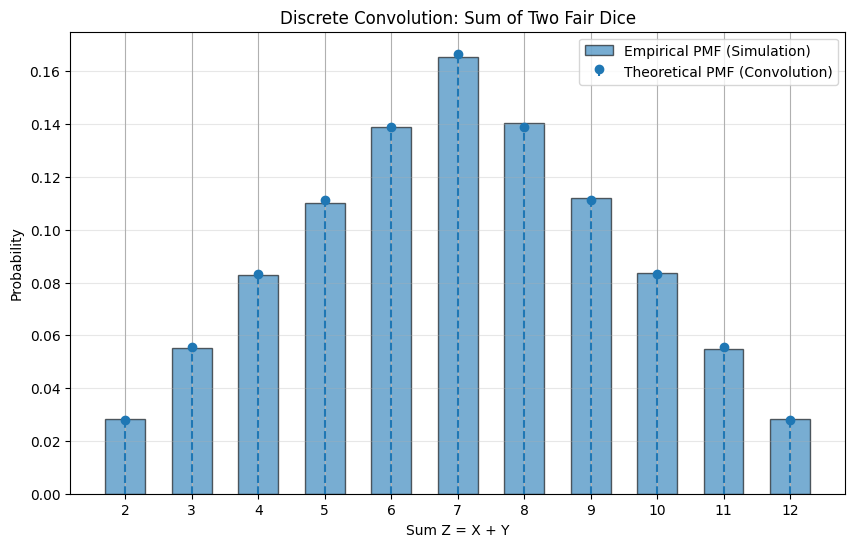

In [38]:
plt.figure(figsize=(10, 6))

# Empirical simulated probabilities
plt.bar(
    z_values,
    empirical_pmf,
    width=0.6,
    alpha=0.6,
    edgecolor="black",
    label="Empirical PMF (Simulation)"
)

# Theoretical convolution
plt.stem(
    z_values,
    pmf_Z,
    linefmt="--",
    markerfmt="o",
    basefmt=" ",
    label="Theoretical PMF (Convolution)"
)

plt.xlabel("Sum Z = X + Y")
plt.ylabel("Probability")
plt.title("Discrete Convolution: Sum of Two Fair Dice")

plt.xticks(z_values)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

# Final Conclusion

### 1. Uniform approximation
A discrete uniform distribution with a small state space has visible gaps. As the state space becomes extremely large, the gaps become negligible and the scaled values visually approach a continuous Uniform(0,1) distribution. The empirical variance approaches the theoretical value \(1/12\).

### 2. Inverse transform
Uniform random variables can be transformed into samples from both continuous and discrete target distributions. The exponential example follows its theoretical PDF, while the discrete example approaches the specified probabilities \(0.2, 0.5, 0.3\).

### 3. Binomial convergence
The sample proportion \(\hat p\) becomes more stable as the number of Bernoulli trials increases. Its variance follows the theoretical relationship \(p(1-p)/n\) and approaches zero.

### 4. Discrete convolution
The simulated sum of two fair dice closely matches the exact PMF obtained using `np.convolve`. This demonstrates how convolution calculates the distribution of the sum of independent discrete random variables.
